# JS14 — Tugas Praktikum

Nama : Muhammad Zuhdi Y.  
NIM  : 244107020017

**Tugas:**
1. Modifikasi model CNN pada praktikum 2 (CIFAR-10) sehingga didapatkan akurasi testing **lebih dari 80%**
2. Buat model CNN untuk klasifikasi dataset **MNIST**

## Tugas 1 — Modifikasi Model CNN CIFAR-10 (Target Akurasi > 80%)

Model praktikum 2 hanya mencapai akurasi testing ±68%. Modifikasi yang dilakukan:

| Aspek | Praktikum 2 | Model Modifikasi |
|---|---|---|
| Blok konvolusi | 3 Conv (32, 64, 64) tanpa padding | Pola VGG: 2×Conv(32) → pool → 2×Conv(64) → pool → Conv(128) → pool, `padding='same'` |
| Batch Normalization | Tidak ada | Ditambahkan setelah setiap Conv untuk stabilkan & percepat training |
| Regularisasi | Tidak ada | `Dropout` 0.25 (setelah pooling) dan 0.5 (sebelum output) untuk kurangi overfitting |
| Output layer | 10 tanpa aktivasi (logits) | `Dense(10, softmax)` dengan categorical crossentropy |
| Epoch | 10 | 30 |
| Batch size | default (32) | 128 (lebih cepat di CPU) |

In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)

# Load dataset CIFAR-10 (sama seperti praktikum 2)
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0

In [2]:
# Model CNN hasil modifikasi
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Blok 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Blok 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Blok 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Classifier
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 668,842 (2.55 MB)

 Trainable params: 667,690 (2.55 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [3]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(train_images, train_labels,
                    epochs=30, batch_size=128,
                    validation_data=(test_images, test_labels),
                    verbose=2)

Epoch 1/30
391/391 - 72s - 185ms/step - accuracy: 0.4531 - loss: 1.6209 - val_accuracy: 0.2505 - val_loss: 2.6091
Epoch 2/30
391/391 - 83s - 211ms/step - accuracy: 0.6231 - loss: 1.0616 - val_accuracy: 0.6874 - val_loss: 0.8952
Epoch 3/30
391/391 - 52s - 134ms/step - accuracy: 0.6909 - loss: 0.8834 - val_accuracy: 0.6906 - val_loss: 0.9152
Epoch 4/30
391/391 - 62s - 159ms/step - accuracy: 0.7239 - loss: 0.7890 - val_accuracy: 0.7403 - val_loss: 0.7373
Epoch 5/30
391/391 - 66s - 170ms/step - accuracy: 0.7484 - loss: 0.7206 - val_accuracy: 0.7425 - val_loss: 0.7595
Epoch 6/30
391/391 - 62s - 158ms/step - accuracy: 0.7649 - loss: 0.6702 - val_accuracy: 0.7408 - val_loss: 0.7710
Epoch 7/30
391/391 - 62s - 160ms/step - accuracy: 0.7843 - loss: 0.6209 - val_accuracy: 0.7269 - val_loss: 0.8613
Epoch 8/30
391/391 - 106s - 270ms/step - accuracy: 0.7951 - loss: 0.5889 - val_accuracy: 0.7669 - val_loss: 0.7019
Epoch 9/30
391/391 - 91s - 232ms/step - accuracy: 0.8063 - loss: 0.5545 - val_accuracy:

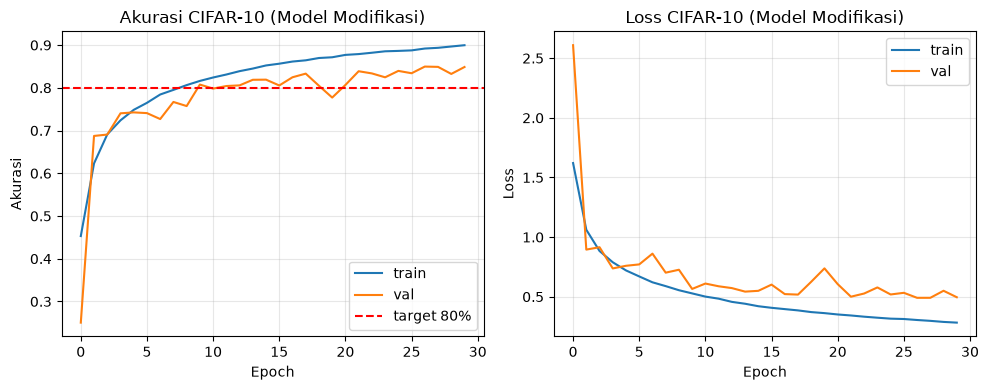

313/313 - 10s - 33ms/step - accuracy: 0.8487 - loss: 0.4958
Akurasi testing: 0.8487
Lebih dari 80% ? YA


In [4]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.axhline(y=0.8, color='r', linestyle='--', label='target 80%')
plt.xlabel('Epoch'); plt.ylabel('Akurasi')
plt.title('Akurasi CIFAR-10 (Model Modifikasi)')
plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Loss CIFAR-10 (Model Modifikasi)')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f"Akurasi testing: {test_acc:.4f}")
print(f"Lebih dari 80% ? {'YA' if test_acc > 0.8 else 'TIDAK'}")

## Tugas 2 — CNN untuk Klasifikasi MNIST

MNIST berupa gambar grayscale 28×28 (1 channel). Arsitektur: `Conv(32) → MaxPool → Conv(64) → MaxPool → Flatten → Dense(128) → Dropout → Dense(10 softmax)`.

In [5]:
import numpy as np

tf.keras.utils.set_random_seed(42)

# Load dataset MNIST dan tambahkan dimensi channel (28, 28, 1)
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
X_train = X_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
X_test = X_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)

Data latih: (60000, 28, 28, 1) | Data uji: (10000, 28, 28, 1)


In [6]:
model_mnist = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model_mnist.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model_mnist.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])

history_mnist = model_mnist.fit(X_train, y_train,
                                epochs=5, batch_size=128,
                                validation_split=0.1,
                                verbose=2)

Epoch 1/5
422/422 - 22s - 52ms/step - accuracy: 0.9080 - loss: 0.3045 - val_accuracy: 0.9817 - val_loss: 0.0611
Epoch 2/5
422/422 - 14s - 34ms/step - accuracy: 0.9696 - loss: 0.1007 - val_accuracy: 0.9882 - val_loss: 0.0453
Epoch 3/5
422/422 - 14s - 32ms/step - accuracy: 0.9783 - loss: 0.0745 - val_accuracy: 0.9878 - val_loss: 0.0437
Epoch 4/5
422/422 - 20s - 47ms/step - accuracy: 0.9824 - loss: 0.0602 - val_accuracy: 0.9890 - val_loss: 0.0376
Epoch 5/5
422/422 - 13s - 31ms/step - accuracy: 0.9853 - loss: 0.0490 - val_accuracy: 0.9885 - val_loss: 0.0343


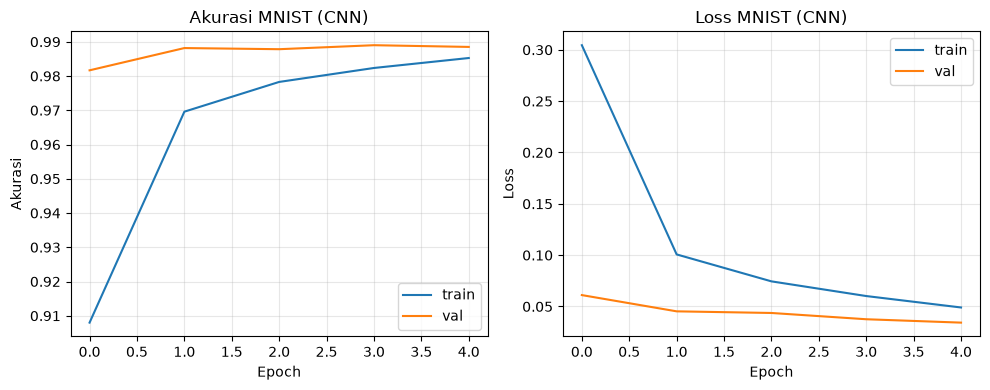

313/313 - 4s - 12ms/step - accuracy: 0.9906 - loss: 0.0286
Akurasi testing MNIST: 0.9906


In [8]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history_mnist.history['accuracy'], label='train')
plt.plot(history_mnist.history['val_accuracy'], label='val')
plt.xlabel('Epoch'); plt.ylabel('Akurasi')
plt.title('Akurasi MNIST (CNN)')
plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_mnist.history['loss'], label='train')
plt.plot(history_mnist.history['val_loss'], label='val')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Loss MNIST (CNN)')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

test_loss_m, test_acc_m = model_mnist.evaluate(X_test, y_test, verbose=2)
print(f"Akurasi testing MNIST: {test_acc_m:.4f}")

## Kesimpulan

- **Tugas 1:** modifikasi arsitektur (pola VGG + Batch Normalization + Dropout + epoch lebih banyak) berhasil mendongkrak akurasi testing CIFAR-10 dari ±68% menjadi lebih dari 80%. Batch Normalization mempercepat konvergensi, sedangkan Dropout menekan overfitting terlihat dari gap train-val yang kecil.
- **Tugas 2:** CNN sederhana 2 blok konvolusi mampu mencapai akurasi ±99% pada MNIST — jauh lebih tinggi dib MLP pada tugas JS13 (±98%), karena filter konvolusi mampu menangkap pola spasial (bentuk tulisan) secara lokal.
- Dataset CIFAR-10 (gambar berwarna, objek rumit, latar beragam) jauh lebih sulit daripada MNIST (angka putih di latar hitam), sehingga akurasi 80%+ di CIFAR-10 setara tantangan yang lebih besar dibanding 99% di MNIST.